# COMP4318/5318 Assignment 2: Image Classification

### Group number: 64    SID1: 540935875, SID2: 550087894, SID3: 520271713, SID4: 510469531

## Setup and dependencies

In [1]:
import os
import sys
import time
from pathlib import Path

# Keras requires backend selection before its first import.
os.environ.setdefault("KERAS_BACKEND", "torch")
LOCAL_DEPS = Path(".deps")
if LOCAL_DEPS.is_dir():
    sys.path.insert(0, str(LOCAL_DEPS.resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split, ParameterGrid
import sklearn
import keras
from keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__, "scikit-learn:", sklearn.__version__)
print("Keras:", keras.__version__, "backend:", keras.backend.backend())

Python: 3.13.2
NumPy: 2.4.4 scikit-learn: 1.6.1
Keras: 3.15.1 backend: torch


## Data loading, exploration, and preprocessing

In [2]:
X_train = np.load('Assignment2Data/X_train.npy')
y_train = np.load('Assignment2Data/y_train.npy')
X_test = np.load('Assignment2Data/X_test.npy')
y_test = np.load('Assignment2Data/y_test.npy')

NUM_CLASSES = len(np.unique(y_train))
print("Training images/labels:", X_train.shape, y_train.shape)
print("Test images/labels:", X_test.shape, y_test.shape)
print("Classes:", NUM_CLASSES, "pixel range:", int(X_train.min()), int(X_train.max()))

Training images/labels: (32000, 28, 28, 3) (32000,)
Test images/labels: (8000, 28, 28, 3) (8000,)
Classes: 9 pixel range: 0 255


 class_id  train_count train_pct  test_count
        0         3490     10.91         873
        1         3431     10.72         858
        2         3505     10.95         877
        3         3656     11.43         914
        4         2950      9.22         737
        5         4290     13.41        1072
        6         2728      8.53         682
        7         3253     10.17         813
        8         4697     14.68        1174
Majority-class baseline: 0.1468
RGB train mean: [188.65 135.93 180.05]
RGB train std: [31.91 45.6  32.18]


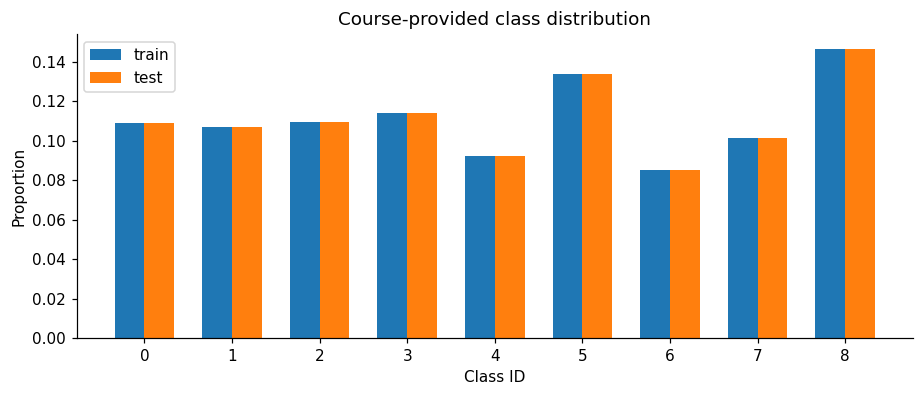

In [3]:
class_ids, train_counts = np.unique(y_train, return_counts=True)
_, test_counts = np.unique(y_test, return_counts=True)
class_table = pd.DataFrame({
    "class_id": class_ids,
    "train_count": train_counts,
    "train_pct": 100 * train_counts / len(y_train),
    "test_count": test_counts,
})
print(class_table.to_string(index=False, formatters={"train_pct": "{:.2f}".format}))
print("Majority-class baseline:", f"{train_counts.max()/len(y_train):.4f}")
print("RGB train mean:", np.round(X_train.mean(axis=(0, 1, 2)), 2))
print("RGB train std:", np.round(X_train.std(axis=(0, 1, 2)), 2))

fig, ax = plt.subplots(figsize=(8.5, 3.7))
ax.bar(class_ids - .17, train_counts / len(y_train), width=.34, label="train")
ax.bar(class_ids + .17, test_counts / len(y_test), width=.34, label="test")
ax.set(xticks=class_ids, xlabel="Class ID", ylabel="Proportion", title="Course-provided class distribution")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "class_balance.png", dpi=180)
plt.show()

### Examples of preprocessed data

The original pixels are unsigned integers in `[0,255]`. Divide by 255 into
`float32` values in `[0,1]` for the neural networks. The 9-class labels remain
integer IDs. For the random forest, use RGB 2×2 mean pooling plus colour
variation and adjacent-pixel difference summaries. This keeps coarse spatial
layout and some texture while reducing the raw 2352 pixels to 597 features.
These are deterministic per-image operations and learn no statistics from the
validation or test samples. An 80/20 stratified validation split is made
*only from the supplied training set* (25,600/6,400 images).

In [4]:
y_train = y_train.astype(np.int64, copy=False)
y_test = y_test.astype(np.int64, copy=False)
X_train_img = X_train.astype(np.float32) / 255.0
X_test_img = X_test.astype(np.float32) / 255.0


def extract_rf_features(images, batch_size=1024):
    '''14x14x3 RGB spatial means + RGB std + horizontal/vertical roughness.'''
    output = np.empty((len(images), 597), dtype=np.float32)
    for start in range(0, len(images), batch_size):
        stop = min(start + batch_size, len(images))
        batch = images[start:stop]
        pooled = batch.reshape(-1, 14, 2, 14, 2, 3).mean(axis=(2, 4)).reshape(-1, 588)
        rgb_std = batch.std(axis=(1, 2))
        horizontal = np.abs(np.diff(batch, axis=2)).mean(axis=(1, 2))
        vertical = np.abs(np.diff(batch, axis=1)).mean(axis=(1, 2))
        output[start:stop] = np.concatenate((pooled, rgb_std, horizontal, vertical), axis=1)
    return output


X_train_rf = extract_rf_features(X_train_img)
X_test_rf = extract_rf_features(X_test_img)
dev_idx, val_idx = train_test_split(
    np.arange(len(y_train)), test_size=.20, stratify=y_train, random_state=SEED,
)
X_dev_img, X_val_img = X_train_img[dev_idx], X_train_img[val_idx]
y_dev, y_val = y_train[dev_idx], y_train[val_idx]
X_dev_rf, X_val_rf = X_train_rf[dev_idx], X_train_rf[val_idx]
print("Neural input:", X_train_img.shape[1:], "range:", (X_train_img.min(), X_train_img.max()))
print("RF input dimension:", X_train_rf.shape[1])
print("Development/validation:", len(dev_idx), len(val_idx))
print("Validation class counts:", np.bincount(y_val, minlength=NUM_CLASSES))

Neural input: (28, 28, 3) range: (np.float32(0.0), np.float32(1.0))
RF input dimension: 597
Development/validation: 25600 6400
Validation class counts: [698 686 701 731 590 858 546 651 939]


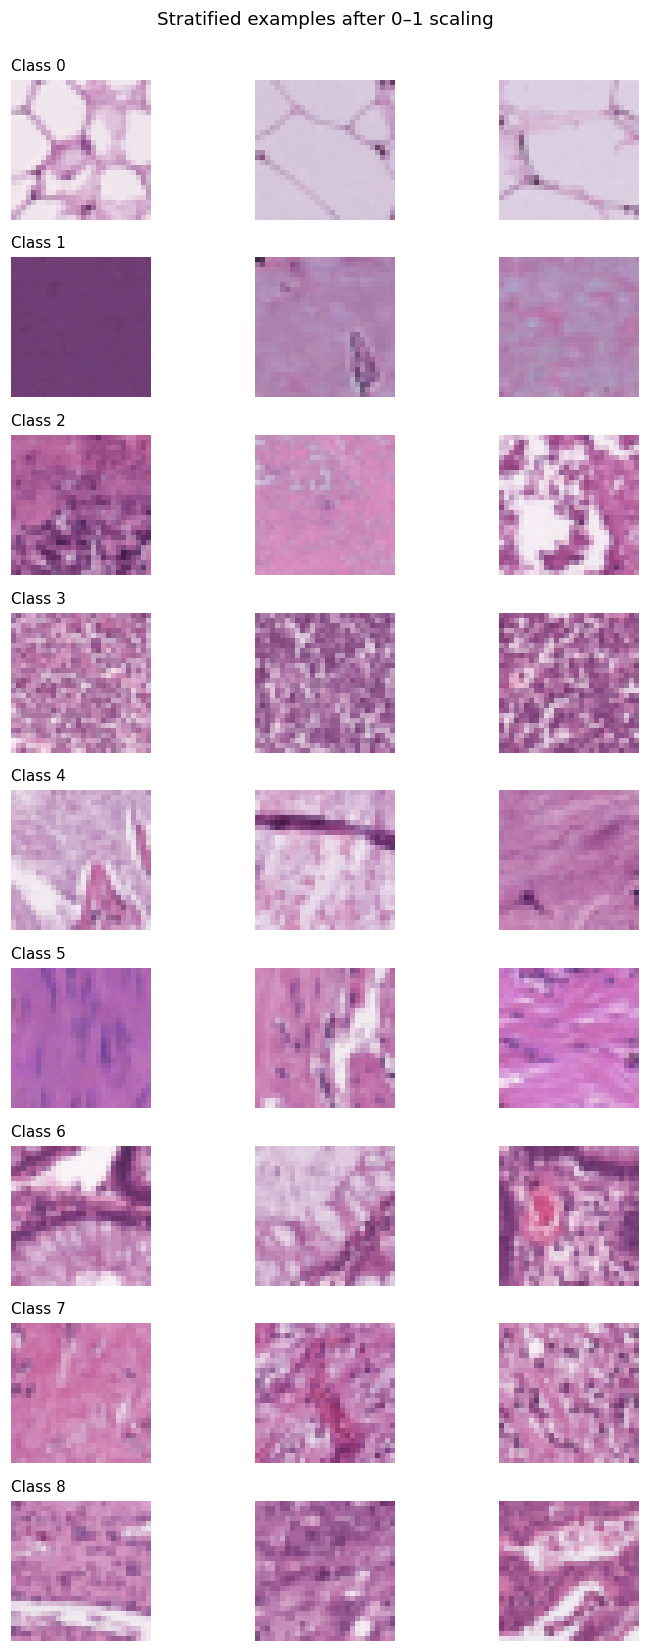

In [5]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(NUM_CLASSES, 3, figsize=(7.4, 15))
for class_id in range(NUM_CLASSES):
    examples = rng.choice(np.flatnonzero(y_train == class_id), size=3, replace=False)
    for column, sample_index in enumerate(examples):
        axes[class_id, column].imshow(X_train_img[sample_index])
        axes[class_id, column].axis("off")
        if column == 0:
            axes[class_id, column].set_title(f"Class {class_id}", loc="left", fontsize=10)
fig.suptitle("Stratified examples after 0–1 scaling", y=.998)
fig.tight_layout()
fig.savefig(FIGURES / "preprocessed_examples.png", dpi=160)
plt.show()

## Algorithm design and setup

### Algorithm of choice from first six weeks of course: Random Forest

The classical baseline is a random forest. Its trees split on pooled colour
and roughness features; bootstrap samples and random feature subsets reduce
similarity among trees. It needs no global normalisation fitted on the test set.
The small initial instance below is trained and evaluated **before** tuning.

In [6]:
def evaluate_labels(true, predicted):
    return {
        "accuracy": float(accuracy_score(true, predicted)),
        "macro_f1": float(f1_score(true, predicted, average="macro", zero_division=0)),
    }


rf_initial = RandomForestClassifier(
    n_estimators=60, max_depth=14, random_state=SEED, n_jobs=4,
)
t0 = time.perf_counter()
rf_initial.fit(X_dev_rf, y_dev)
rf_initial_seconds = time.perf_counter() - t0
rf_initial_metrics = evaluate_labels(y_val, rf_initial.predict(X_val_rf))
print("Initial RF:", rf_initial_metrics, "fit seconds:", f"{rf_initial_seconds:.2f}")

Initial RF: {'accuracy': 0.70484375, 'macro_f1': 0.6872518197926802} fit seconds: 11.54


### Fully connected neural network

Flatten all 28×28×3 pixels, then use two learned Dense layers with batch
normalisation, ReLU, dropout and a 9-way softmax. This can learn feature interactions, but flattening
discards explicit neighbourhood structure and increases the first layer's
parameter count. The initial instance is evaluated here, before tuning.

In [7]:
def build_mlp(hidden_units=256, dropout=.10, learning_rate=.0005):
    model = keras.Sequential([
        layers.Input(shape=(28, 28, 3)),
        layers.Flatten(),
        layers.Dense(hidden_units, use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(dropout),
        layers.Dense(hidden_units // 2, use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(dropout),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy", metrics=["accuracy"],
    )
    return model


keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
mlp_initial = build_mlp()
t0 = time.perf_counter()
mlp_initial_history = mlp_initial.fit(
    X_dev_img, y_dev, validation_data=(X_val_img, y_val),
    epochs=5, batch_size=128, verbose=0,
)
mlp_initial_seconds = time.perf_counter() - t0
print("Initial MLP parameters:", mlp_initial.count_params())
print("Initial MLP best validation accuracy:", f"{max(mlp_initial_history.history['val_accuracy']):.4f}")
print("Initial MLP fit seconds:", f"{mlp_initial_seconds:.2f}")

Initial MLP parameters: 637577
Initial MLP best validation accuracy: 0.3541
Initial MLP fit seconds: 17.42


### Convolutional neural network

Two trainable 3×3 convolution blocks with max pooling learn local patterns;
a compact Dense layer combines them for nine-class prediction. The network is
defined from basic Keras layers, without pretrained or application models.
Its initial instance is trained and evaluated before tuning.

In [8]:
def build_cnn(filters=16, dropout=.20, learning_rate=.001):
    model = keras.Sequential([
        layers.Input(shape=(28, 28, 3)),
        layers.Conv2D(filters, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(pool_size=2),
        layers.Conv2D(2 * filters, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(pool_size=2),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dropout(dropout),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy", metrics=["accuracy"],
    )
    return model


keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
cnn_initial = build_cnn()
t0 = time.perf_counter()
cnn_initial_history = cnn_initial.fit(
    X_dev_img, y_dev, validation_data=(X_val_img, y_val),
    epochs=5, batch_size=128, verbose=0,
)
cnn_initial_seconds = time.perf_counter() - t0
print("Initial CNN parameters:", cnn_initial.count_params())
print("Initial CNN best validation accuracy:", f"{max(cnn_initial_history.history['val_accuracy']):.4f}")
print("Initial CNN fit seconds:", f"{cnn_initial_seconds:.2f}")

Initial CNN parameters: 106089
Initial CNN best validation accuracy: 0.6698
Initial CNN fit seconds: 30.74


## Hyperparameter tuning

Each search below uses the same untouched 6,400-image validation subset.
It records every candidate's validation accuracy, macro F1 and wall-clock
time. The test labels are never used to select settings. The MLP and CNN each
search three different hyperparameters; a small full factorial grid keeps
runtime practical. MLP candidates have up to 30 epochs with learning-rate
reduction and early stopping, while CNN candidates have up to 10 epochs.
The best candidate is chosen by validation accuracy;
macro F1 breaks exact ties, then the candidate order provides a stable result.

### Algorithm of choice from first six weeks of course: Random Forest

RF  1/8: {'max_depth': 12, 'min_samples_leaf': 1, 'n_estimators': 60}, val_acc=0.6941, val_macro_f1=0.6718, seconds=10.12
RF  2/8: {'max_depth': 12, 'min_samples_leaf': 1, 'n_estimators': 120}, val_acc=0.6997, val_macro_f1=0.6768, seconds=19.80
RF  3/8: {'max_depth': 12, 'min_samples_leaf': 3, 'n_estimators': 60}, val_acc=0.6970, val_macro_f1=0.6739, seconds=9.68
RF  4/8: {'max_depth': 12, 'min_samples_leaf': 3, 'n_estimators': 120}, val_acc=0.7008, val_macro_f1=0.6784, seconds=19.36
RF  5/8: {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 60}, val_acc=0.7164, val_macro_f1=0.7008, seconds=14.06
RF  6/8: {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 120}, val_acc=0.7239, val_macro_f1=0.7078, seconds=26.77
RF  7/8: {'max_depth': 20, 'min_samples_leaf': 3, 'n_estimators': 60}, val_acc=0.7211, val_macro_f1=0.7050, seconds=12.86
RF  8/8: {'max_depth': 20, 'min_samples_leaf': 3, 'n_estimators': 120}, val_acc=0.7238, val_macro_f1=0.7077, seconds=25.90
Best RF validation co

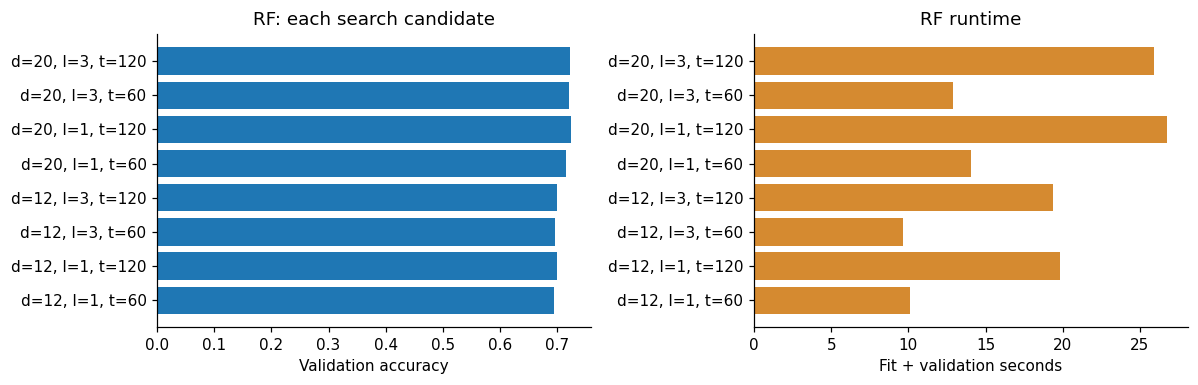

In [9]:
rf_grid = list(ParameterGrid({
    "n_estimators": [60, 120],
    "max_depth": [12, 20],
    "min_samples_leaf": [1, 3],
}))
rf_search_rows = []
for number, config in enumerate(rf_grid, start=1):
    model = RandomForestClassifier(**config, random_state=SEED, n_jobs=4)
    t0 = time.perf_counter()
    model.fit(X_dev_rf, y_dev)
    predicted = model.predict(X_val_rf)
    elapsed = time.perf_counter() - t0
    scores = evaluate_labels(y_val, predicted)
    row = {**config, **scores, "seconds": elapsed}
    rf_search_rows.append(row)
    print(f"RF {number:2d}/{len(rf_grid)}: {config}, val_acc={scores['accuracy']:.4f}, "
          f"val_macro_f1={scores['macro_f1']:.4f}, seconds={elapsed:.2f}")

rf_search_table = pd.DataFrame(rf_search_rows)
rf_selected = sorted(rf_search_rows, key=lambda r: (r["accuracy"], r["macro_f1"]), reverse=True)[0]
print("Best RF validation configuration:", rf_selected)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
labels = [f"d={r['max_depth']}, l={r['min_samples_leaf']}, t={r['n_estimators']}" for r in rf_search_rows]
axes[0].barh(labels, rf_search_table["accuracy"])
axes[0].set(xlabel="Validation accuracy", title="RF: each search candidate")
axes[1].barh(labels, rf_search_table["seconds"], color="#d58a30")
axes[1].set(xlabel="Fit + validation seconds", title="RF runtime")
fig.tight_layout()
fig.savefig(FIGURES / "rf_tuning.png", dpi=160)
plt.show()

### Fully connected neural network

MLP  1/8: {'dropout': 0.1, 'hidden_units': 128, 'learning_rate': 0.0005}, val_acc=0.6377, val_macro_f1=0.6199, best_epoch=30, seconds=81.54
MLP  2/8: {'dropout': 0.1, 'hidden_units': 128, 'learning_rate': 0.001}, val_acc=0.6472, val_macro_f1=0.6338, best_epoch=30, seconds=81.99
MLP  3/8: {'dropout': 0.1, 'hidden_units': 256, 'learning_rate': 0.0005}, val_acc=0.6425, val_macro_f1=0.6348, best_epoch=30, seconds=89.33
MLP  4/8: {'dropout': 0.1, 'hidden_units': 256, 'learning_rate': 0.001}, val_acc=0.5950, val_macro_f1=0.5720, best_epoch=23, seconds=85.09
MLP  5/8: {'dropout': 0.25, 'hidden_units': 128, 'learning_rate': 0.0005}, val_acc=0.6559, val_macro_f1=0.6354, best_epoch=27, seconds=73.05
MLP  6/8: {'dropout': 0.25, 'hidden_units': 128, 'learning_rate': 0.001}, val_acc=0.6591, val_macro_f1=0.6413, best_epoch=29, seconds=74.03
MLP  7/8: {'dropout': 0.25, 'hidden_units': 256, 'learning_rate': 0.0005}, val_acc=0.6622, val_macro_f1=0.6479, best_epoch=27, seconds=93.44
MLP  8/8: {'dropout'

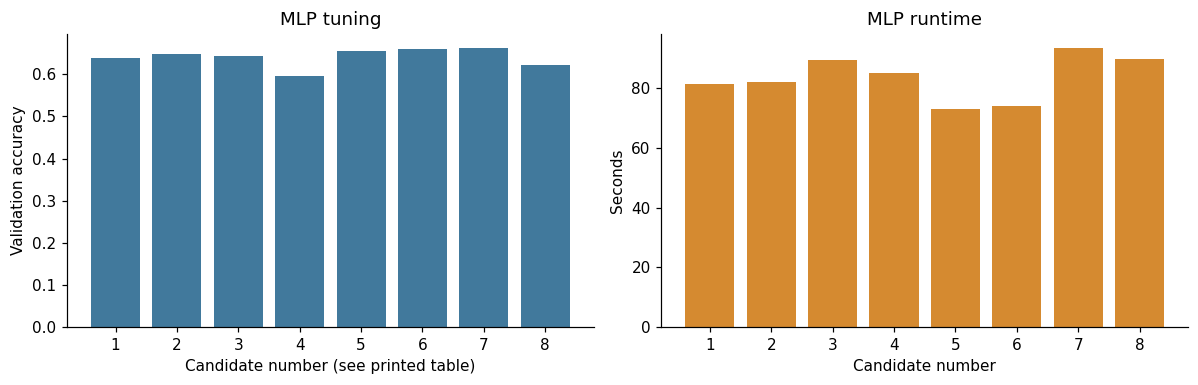

In [10]:
def search_neural_network(name, build_model, grid, max_epochs=10, patience=2,
                          reduce_lr=False):
    rows = []
    histories = []
    for number, config in enumerate(list(ParameterGrid(grid)), start=1):
        keras.backend.clear_session()
        keras.utils.set_random_seed(SEED)
        model = build_model(**config)
        stopper = keras.callbacks.EarlyStopping(
            monitor="val_accuracy", mode="max", patience=patience, restore_best_weights=True,
        )
        callbacks = [stopper]
        if reduce_lr:
            callbacks.append(keras.callbacks.ReduceLROnPlateau(
                monitor="val_loss", factor=.5, patience=3, min_lr=.00001,
            ))
        t0 = time.perf_counter()
        history = model.fit(
            X_dev_img, y_dev, validation_data=(X_val_img, y_val),
            epochs=max_epochs, batch_size=128, callbacks=callbacks, verbose=0,
        )
        predicted = model.predict(X_val_img, batch_size=256, verbose=0).argmax(axis=1)
        elapsed = time.perf_counter() - t0
        scores = evaluate_labels(y_val, predicted)
        best_epoch = int(np.argmax(history.history["val_accuracy"]) + 1)
        row = {**config, **scores, "best_epoch": best_epoch,
               "epochs_ran": len(history.history["loss"]), "seconds": elapsed}
        rows.append(row)
        histories.append(history.history)
        print(f"{name} {number:2d}/{len(ParameterGrid(grid))}: {config}, "
              f"val_acc={scores['accuracy']:.4f}, val_macro_f1={scores['macro_f1']:.4f}, "
              f"best_epoch={best_epoch}, seconds={elapsed:.2f}")
        del model
    best_index = max(range(len(rows)), key=lambda i: (rows[i]["accuracy"], rows[i]["macro_f1"]))
    return pd.DataFrame(rows), best_index, histories


mlp_grid = {
    "hidden_units": [128, 256],
    "dropout": [.10, .25],
    "learning_rate": [.0005, .001],
}
mlp_search_table, mlp_best_index, mlp_search_histories = search_neural_network(
    "MLP", build_mlp, mlp_grid, max_epochs=30, patience=6, reduce_lr=True,
)
print("Best MLP validation configuration:", mlp_search_table.iloc[mlp_best_index].to_dict())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
numbers = np.arange(1, len(mlp_search_table) + 1)
axes[0].bar(numbers, mlp_search_table["accuracy"], color="#41799c")
axes[0].set(xlabel="Candidate number (see printed table)", ylabel="Validation accuracy", title="MLP tuning")
axes[1].bar(numbers, mlp_search_table["seconds"], color="#d58a30")
axes[1].set(xlabel="Candidate number", ylabel="Seconds", title="MLP runtime")
fig.tight_layout()
fig.savefig(FIGURES / "mlp_tuning.png", dpi=160)
plt.show()

### Convolutional neural network

CNN  1/8: {'dropout': 0.15, 'filters': 16, 'learning_rate': 0.0003}, val_acc=0.7055, val_macro_f1=0.6995, best_epoch=10, seconds=58.39
CNN  2/8: {'dropout': 0.15, 'filters': 16, 'learning_rate': 0.001}, val_acc=0.7348, val_macro_f1=0.7247, best_epoch=9, seconds=59.80
CNN  3/8: {'dropout': 0.15, 'filters': 24, 'learning_rate': 0.0003}, val_acc=0.6881, val_macro_f1=0.6831, best_epoch=9, seconds=86.34
CNN  4/8: {'dropout': 0.15, 'filters': 24, 'learning_rate': 0.001}, val_acc=0.7584, val_macro_f1=0.7452, best_epoch=9, seconds=85.46
CNN  5/8: {'dropout': 0.35, 'filters': 16, 'learning_rate': 0.0003}, val_acc=0.6933, val_macro_f1=0.6799, best_epoch=10, seconds=60.98
CNN  6/8: {'dropout': 0.35, 'filters': 16, 'learning_rate': 0.001}, val_acc=0.7450, val_macro_f1=0.7330, best_epoch=10, seconds=60.49
CNN  7/8: {'dropout': 0.35, 'filters': 24, 'learning_rate': 0.0003}, val_acc=0.6753, val_macro_f1=0.6600, best_epoch=10, seconds=89.47
CNN  8/8: {'dropout': 0.35, 'filters': 24, 'learning_rate': 0

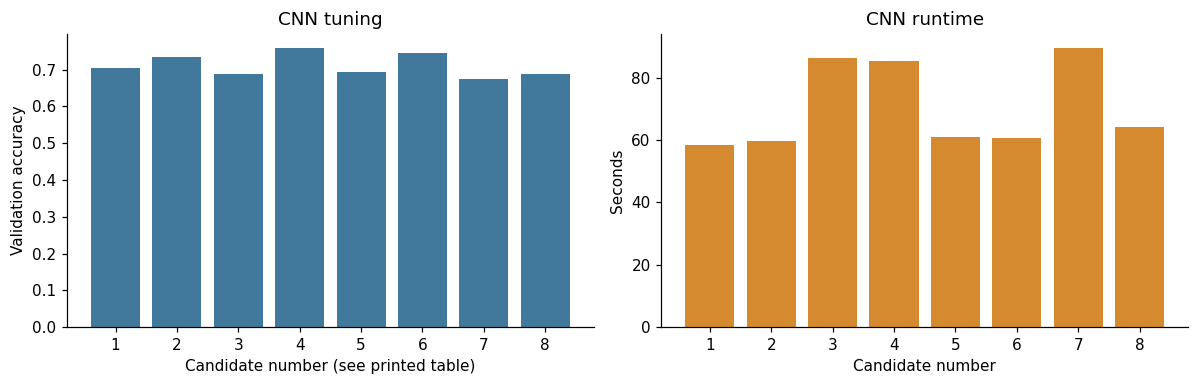

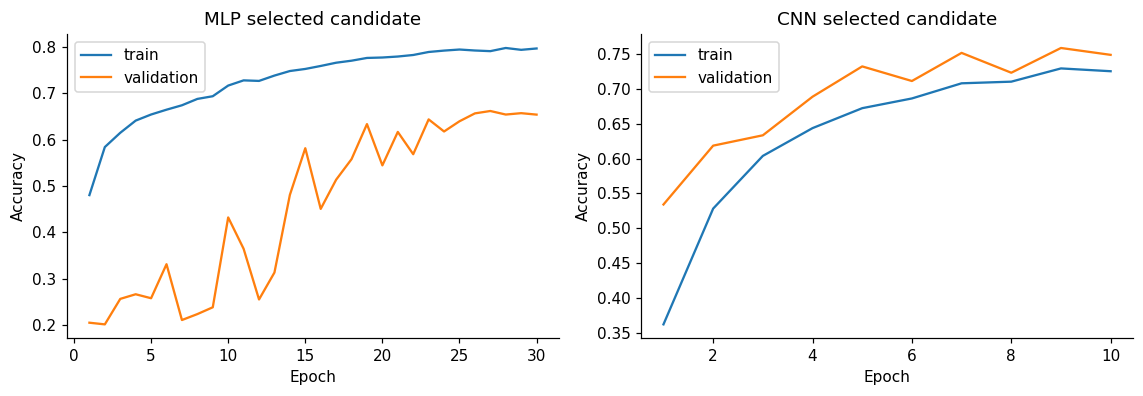

In [11]:
cnn_grid = {
    "filters": [16, 24],
    "dropout": [.15, .35],
    "learning_rate": [.0003, .001],
}
cnn_search_table, cnn_best_index, cnn_search_histories = search_neural_network(
    "CNN", build_cnn, cnn_grid,
)
print("Best CNN validation configuration:", cnn_search_table.iloc[cnn_best_index].to_dict())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
numbers = np.arange(1, len(cnn_search_table) + 1)
axes[0].bar(numbers, cnn_search_table["accuracy"], color="#41799c")
axes[0].set(xlabel="Candidate number (see printed table)", ylabel="Validation accuracy", title="CNN tuning")
axes[1].bar(numbers, cnn_search_table["seconds"], color="#d58a30")
axes[1].set(xlabel="Candidate number", ylabel="Seconds", title="CNN runtime")
fig.tight_layout()
fig.savefig(FIGURES / "cnn_tuning.png", dpi=160)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.7))
for ax, title, histories, best_index in (
    (axes[0], "MLP selected candidate", mlp_search_histories, mlp_best_index),
    (axes[1], "CNN selected candidate", cnn_search_histories, cnn_best_index),
):
    chosen = histories[best_index]
    ax.plot(np.arange(1, len(chosen["accuracy"]) + 1), chosen["accuracy"], label="train")
    ax.plot(np.arange(1, len(chosen["val_accuracy"]) + 1), chosen["val_accuracy"], label="validation")
    ax.set(xlabel="Epoch", ylabel="Accuracy", title=title)
    ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "learning_curves.png", dpi=160)
plt.show()

## Final models

### Algorithm of choice from first six weeks of course: Random Forest

In [12]:
FINAL_RF = {"max_depth": 20, "min_samples_leaf": 1, "n_estimators": 120}
final_results = {}
final_predictions = {}

rf_final = RandomForestClassifier(**FINAL_RF, random_state=SEED, n_jobs=4)
t0 = time.perf_counter()
rf_final.fit(X_train_rf, y_train)
rf_fit_seconds = time.perf_counter() - t0
t0 = time.perf_counter()
rf_pred = rf_final.predict(X_test_rf)
rf_predict_seconds = time.perf_counter() - t0
final_predictions["Random Forest"] = rf_pred
final_results["Random Forest"] = {
    "params": FINAL_RF, **evaluate_labels(y_test, rf_pred),
    "weighted_f1": float(f1_score(y_test, rf_pred, average="weighted", zero_division=0)),
    "fit_seconds": rf_fit_seconds, "predict_seconds": rf_predict_seconds,
    "representation_size": X_train_rf.shape[1],
}
print("Final RF:", final_results["Random Forest"])

Final RF: {'params': {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 120}, 'accuracy': 0.729375, 'macro_f1': 0.7147312019475783, 'weighted_f1': 0.7227142957086914, 'fit_seconds': 34.99753219995182, 'predict_seconds': 0.14241869992110878, 'representation_size': 597}


### Fully connected neural network

In [16]:
FINAL_MLP = {"hidden_units": 256, "dropout": .25, "learning_rate": .0005}
FINAL_MLP_EPOCHS = 27
# Frozen from this notebook's saved MLP search winner (candidate 7):
# validation accuracy 0.6621875, macro F1 0.6478767703832315, best epoch 27.
# The retained history records the learning rates USED during each epoch.
# Reductions first apply at epochs 10, 14, 19, 23 and 26.
# Literal settings keep this cell independent of the expensive search cells.
FINAL_MLP_LR_HALVING_EPOCHS = (10, 14, 19, 23, 26)


def final_mlp_learning_rate(epoch, current_lr):
    halvings = sum(epoch + 1 >= milestone for milestone in FINAL_MLP_LR_HALVING_EPOCHS)
    return FINAL_MLP["learning_rate"] / (2 ** halvings)


keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
mlp_final = build_mlp(**FINAL_MLP)
t0 = time.perf_counter()
mlp_final_history = mlp_final.fit(
    X_train_img, y_train, epochs=FINAL_MLP_EPOCHS, batch_size=128, verbose=0,
    callbacks=[keras.callbacks.LearningRateScheduler(final_mlp_learning_rate)],
)
mlp_fit_seconds = time.perf_counter() - t0
t0 = time.perf_counter()
mlp_pred = mlp_final.predict(X_test_img, batch_size=256, verbose=0).argmax(axis=1)
mlp_predict_seconds = time.perf_counter() - t0
final_predictions["MLP"] = mlp_pred
final_results["MLP"] = {
    "params": {**FINAL_MLP, "epochs": FINAL_MLP_EPOCHS,
               "lr_halving_epochs": FINAL_MLP_LR_HALVING_EPOCHS},
    **evaluate_labels(y_test, mlp_pred),
    "weighted_f1": float(f1_score(y_test, mlp_pred, average="weighted", zero_division=0)),
    "fit_seconds": mlp_fit_seconds, "predict_seconds": mlp_predict_seconds,
    "parameter_count": mlp_final.count_params(),
}
print("Final MLP:", final_results["MLP"])

Final MLP: {'params': {'hidden_units': 256, 'dropout': 0.25, 'learning_rate': 0.0005, 'epochs': 27, 'lr_halving_epochs': (10, 14, 19, 23, 26)}, 'accuracy': 0.665625, 'macro_f1': 0.6556846692769173, 'weighted_f1': 0.663073075706918, 'fit_seconds': 97.65400179999415, 'predict_seconds': 0.35663559997919947, 'parameter_count': 637577}


### Convolutional neural network

In [14]:
FINAL_CNN = {"filters": 24, "dropout": .15, "learning_rate": .001}
FINAL_CNN_EPOCHS = 9
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
cnn_final = build_cnn(**FINAL_CNN)
t0 = time.perf_counter()
cnn_final_history = cnn_final.fit(
    X_train_img, y_train, epochs=FINAL_CNN_EPOCHS, batch_size=128, verbose=0,
)
cnn_fit_seconds = time.perf_counter() - t0
t0 = time.perf_counter()
cnn_pred = cnn_final.predict(X_test_img, batch_size=256, verbose=0).argmax(axis=1)
cnn_predict_seconds = time.perf_counter() - t0
final_predictions["CNN"] = cnn_pred
final_results["CNN"] = {
    "params": {**FINAL_CNN, "epochs": FINAL_CNN_EPOCHS},
    **evaluate_labels(y_test, cnn_pred),
    "weighted_f1": float(f1_score(y_test, cnn_pred, average="weighted", zero_division=0)),
    "fit_seconds": cnn_fit_seconds, "predict_seconds": cnn_predict_seconds,
    "parameter_count": cnn_final.count_params(),
}
print("Final CNN:", final_results["CNN"])

Final CNN: {'params': {'filters': 24, 'dropout': 0.15, 'learning_rate': 0.001, 'epochs': 9}, 'accuracy': 0.765875, 'macro_f1': 0.7572230740644659, 'weighted_f1': 0.762185774293479, 'fit_seconds': 88.87660509999841, 'predict_seconds': 1.1338628999656066, 'parameter_count': 162265}


### Side-by-side test comparison

The confusion matrices use actual classes as rows and predicted classes as
columns. Class-wise recall helps reveal weaknesses hidden by overall accuracy.

Selected final settings:
  Random Forest: {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 120}
  MLP: {'hidden_units': 256, 'dropout': 0.25, 'learning_rate': 0.0005, 'epochs': 27, 'lr_halving_epochs': (10, 14, 19, 23, 26)}
  CNN: {'filters': 24, 'dropout': 0.15, 'learning_rate': 0.001, 'epochs': 9}
Test metrics and times:
               accuracy  macro_f1  weighted_f1  fit_seconds  predict_seconds
Random Forest    0.7294    0.7147       0.7227      34.9975           0.1424
MLP              0.6656    0.6557       0.6631      97.6540           0.3566
CNN              0.7659    0.7572       0.7622      88.8766           1.1339


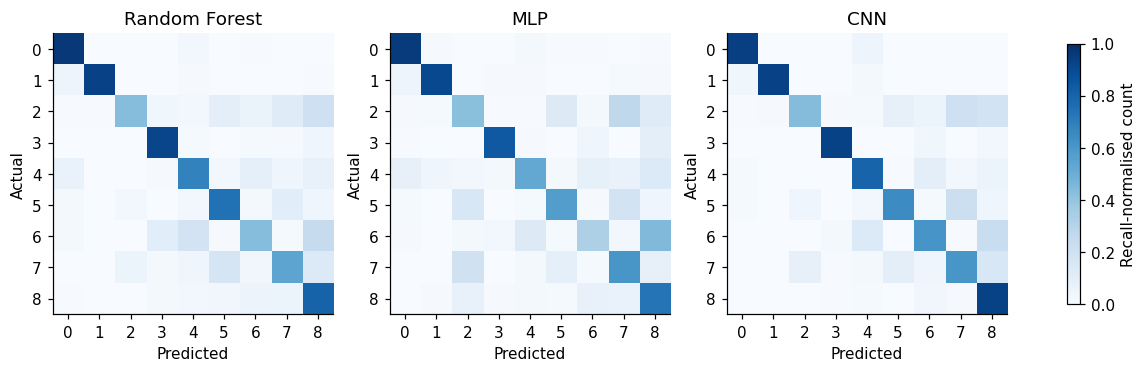


 Random Forest per-class precision, recall and F1
              precision    recall  f1-score   support

           0     0.8593    0.9656    0.9094       873
           1     0.9925    0.9301    0.9603       858
           2     0.8326    0.4310    0.5680       877
           3     0.8436    0.9147    0.8777       914
           4     0.6303    0.6825    0.6554       737
           5     0.7342    0.7472    0.7406      1072
           6     0.5297    0.4311    0.4753       682
           7     0.5676    0.5424    0.5547       813
           8     0.6075    0.8015    0.6911      1174

    accuracy                         0.7294      8000
   macro avg     0.7330    0.7162    0.7147      8000
weighted avg     0.7363    0.7294    0.7227      8000


 MLP per-class precision, recall and F1
              precision    recall  f1-score   support

           0     0.8544    0.9542    0.9015       873
           1     0.9205    0.9044    0.9124       858
           2     0.4525    0.4185    0.4

In [17]:
comparison = pd.DataFrame({
    name: {key: result[key] for key in
           ("accuracy", "macro_f1", "weighted_f1", "fit_seconds", "predict_seconds")}
    for name, result in final_results.items()
}).T
print("Selected final settings:")
for name, result in final_results.items():
    print(f"  {name}: {result['params']}")
print("Test metrics and times:")
print(comparison.to_string(float_format=lambda x: f"{x:.4f}"))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.1))
for ax, (name, predicted) in zip(axes, final_predictions.items()):
    matrix = confusion_matrix(y_test, predicted, labels=class_ids)
    display = matrix / matrix.sum(axis=1, keepdims=True)
    image = ax.imshow(display, vmin=0, vmax=1, cmap="Blues")
    ax.set(title=name, xlabel="Predicted", ylabel="Actual",
           xticks=np.arange(NUM_CLASSES), yticks=np.arange(NUM_CLASSES))
fig.colorbar(image, ax=axes, label="Recall-normalised count", shrink=.75)
fig.savefig(FIGURES / "test_confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()

for name, predicted in final_predictions.items():
    print("\n", name, "per-class precision, recall and F1")
    print(classification_report(y_test, predicted, labels=class_ids, zero_division=0, digits=4))

## AI Acknowledgement

Since most of us are non-native English speakers, we used the AI tool OpenAI ChatGPT (https://chatgpt.com) to help us polish and revise the text part in this assignment. We also used it for some assistance for python code syntax, especially the plot part. The remaining parts were all completed by us.